In [2]:
import numpy as np
import librosa
import librosa.display
from utils import (
    plot_ondas,
    samples_format,
    closest_factors,
    get_matrix_from_samples,
    split_array,
    format_values_to_img,
    export_img,
    show_img,
    get_matrix_from_img,
    decode_rgb_matrix,
    combine_matrix,
    unnormalize_matrix,
    export_audio,
    comprimir_primer_nivel_optimizado,
    descomprimir_primer_nivel
)

# Cargar el archivo de audio
audio_file = "audio_muestra.mp3"
y, sr = librosa.load(audio_file, sr=44100)

In [3]:
samples = samples_format(y)

In [7]:
seg=44100

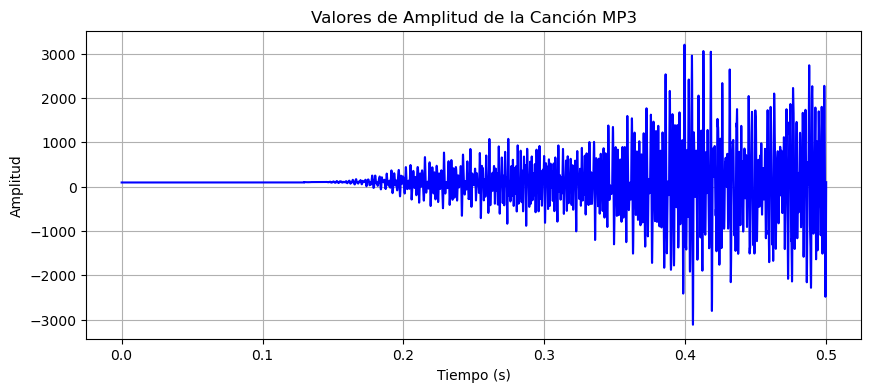

In [12]:
plot_ondas(samples[:int(seg*0.5)],44100)

In [37]:
from collections import Counter
mode=Counter(samples)
print(mode.most_common())

[(0, 2146), (94, 1821), (95, 1718), (93, 1391), (102, 1294), (103, 1290), (104, 1281), (109, 1279), (96, 1261), (120, 1256), (87, 1256), (92, 1249), (89, 1248), (110, 1237), (74, 1235), (43, 1227), (98, 1224), (91, 1224), (85, 1221), (88, 1220), (81, 1216), (77, 1216), (166, 1214), (116, 1212), (51, 1212), (72, 1207), (69, 1206), (73, 1204), (63, 1204), (70, 1203), (82, 1202), (84, 1201), (68, 1201), (164, 1201), (113, 1200), (99, 1198), (118, 1198), (23, 1197), (108, 1196), (90, 1196), (50, 1195), (36, 1195), (107, 1193), (121, 1193), (117, 1189), (159, 1189), (114, 1188), (80, 1187), (194, 1187), (83, 1186), (49, 1186), (131, 1183), (79, 1179), (115, 1178), (119, 1178), (100, 1175), (75, 1174), (59, 1173), (45, 1172), (67, 1171), (54, 1171), (37, 1169), (55, 1168), (177, 1168), (97, 1167), (128, 1167), (139, 1166), (64, 1166), (62, 1165), (122, 1164), (133, 1164), (13, 1164), (101, 1163), (76, 1163), (61, 1163), (-8, 1162), (106, 1161), (78, 1161), (129, 1160), (-17, 1160), (105, 115

In [ ]:
def comprimir_segundo_nivel(comprimido, cuentas):
    # Encontrar los índices donde comprimido cambia de valor
    cambios = np.where(comprimido[:-1] != comprimido[1:])[0] + 1
    # Dividir los arrays en segmentos donde comprimido tiene el mismo valor
    segmentos_comprimido = np.split(comprimido, cambios)
    segmentos_cuentas = np.split(cuentas, cambios)
    # Inicializar listas para los resultados
    comprimido = []
    cuenta_array = []
    # Procesar cada segmento
    for index,comprimido_segmento in enumerate(segmentos_comprimido):
        cuenta_segmento = segmentos_cuentas[index]
        comprimido.append(comprimido_segmento[0])
        cuenta_array.append(cuenta_segmento[0])
    return (
        np.array(comprimido),
        np.array(cuenta_array),
    )

In [16]:
print(samples.shape)

(7993344,)


In [4]:
samples_vectors=np.array([[sample,index+1] for index,sample in enumerate(samples)])

In [18]:
from sklearn.base import BaseEstimator, ClusterMixin
import numpy as np


class KMedianas(BaseEstimator, ClusterMixin):
    def __init__(self, n_clusters=2, max_iter=100):
        self.n_clusters = n_clusters
        self.max_iter = max_iter

    def fit(self, X, y=None):
        # Inicializar los centroides como elementos aleatorios de X
        indices = np.random.choice(X.shape[0], self.n_clusters, replace=False)
        self.centroids = X[indices]

        for _ in range(self.max_iter):
            # Asignar cada elemento al cluster cuyo centroide es más cercano
            labels = np.argmin(
                np.sum((X[:, np.newaxis] - self.centroids) ** 2, axis=2), axis=1
            )

            # Recalcular los centroides como la mediana de cada cluster
            new_centroids = np.array(
                [np.median(X[labels == i], axis=0) for i in range(self.n_clusters)]
            )

            # Si los centroides no han cambiado, terminar
            if np.all(self.centroids == new_centroids):
                break

            self.centroids = new_centroids

        self.labels_ = labels
        return self

In [5]:
from sklearn.cluster import KMeans

# Crear una instancia de KMeans
kmeans = KMeans(n_clusters=360, random_state=0)

# Ajustar el modelo a tus datos
resultado = kmeans.fit(samples_vectors)

# Los centroides de los clusters están disponibles en 'cluster_centers_'
centroides = resultado.cluster_centers_

# Las etiquetas de los clusters para cada punto de datos están disponibles en 'labels_'
etiquetas = resultado.labels_

In [10]:
print(resultado)

KMeans(n_clusters=360, random_state=0)


In [20]:
print(centroides[:25])
print(etiquetas[:44100])

[[-1.24441478e+04  4.39299973e+06]
 [-2.68466274e+03  1.39035344e+06]
 [-8.70118089e+01  6.68887041e+06]
 [ 9.40541421e+01  2.68589000e+05]
 [-1.93572367e+03  2.50506571e+06]
 [-1.82846711e+03  5.42798463e+06]
 [ 9.86604604e+01  7.53699950e+06]
 [ 9.43237216e+01  3.31581300e+06]
 [ 9.44696634e+01  8.59065000e+05]
 [ 8.59972938e+01  5.87410000e+06]
 [ 1.89480597e+03  1.98260004e+06]
 [ 2.83421486e+02  3.67934607e+06]
 [ 7.54682710e+03  4.99398288e+06]
 [ 9.23423741e+01  6.31341000e+06]
 [-3.83324095e+03  7.18510989e+06]
 [ 9.43699653e+01  7.94065050e+06]
 [ 1.99463887e+03  2.94043669e+06]
 [-1.07840230e+03  4.08965754e+06]
 [ 7.53998904e+02  4.69525520e+06]
 [ 1.19505742e+02  1.64415354e+06]
 [ 5.35741963e+03  6.96313930e+06]
 [ 9.55849594e+01  5.27736000e+05]
 [ 1.01173741e+04  1.13501960e+06]
 [ 1.30110596e+02  5.59652048e+06]
 [ 9.70531420e+01  1.51580000e+04]]
[ 24  24  24 ... 152 152 152]


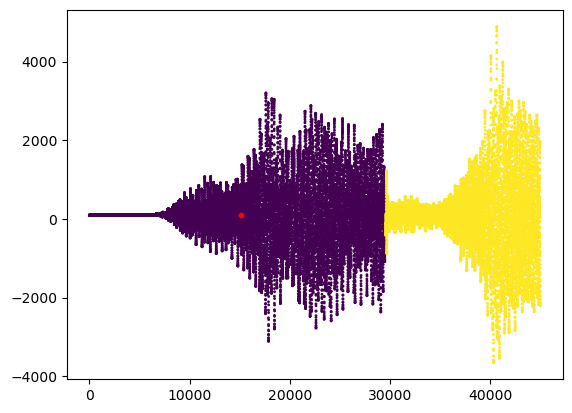

In [48]:
import matplotlib.pyplot as plt
plt.scatter(samples_vectors[:45000, 1], samples_vectors[:45000, 0], c=etiquetas[:45000], s=1)
plt.scatter(centroides[24, 1], centroides[24, 0], c='red', s=10)
plt.show()


In [37]:
transformada = np.fft.fft(samples[:44100])

# Conservar solo los primeros n componentes de frecuencia
# n = 100
# transformada[n:-n] = 0

# Reconstruir las muestras a partir de la Transformada de Fourier
muestras_reconstruidas = np.fft.ifft(transformada)

In [46]:
print(transformada.shape)

(44100,)


In [47]:
print(np.round(np.real(transformada[:100])).astype(int))

[4260124   14934  -40654   -7773   22221   25185   24791   12755    3377
    6741    4360   11386   13279   19338   19842   12887    5090   17478
    7761   -2610   18290   15210   -1597    7821   19369     698     224
   15999   13950    7231   14449   16898    8342    9790   15646   10849
    8096   16663   12661    6945   12188    9221   10955   12995   15327
    7912   15315   11409    9031   14634    9131   13629   13990   13230
    7363   16560    4413   13222   13819    6432   11695   15206   10946
   12022    7507   14932    8346   15817   13232   -4538   26383  -12855
   27883   -3959   26602    9432   18357   15485   14380   17086   10090
   15505   13933   10290   14271   10541   11431   10539   16076   13068
   14756   16622   13828   13770   12220    8533   13200   13209   12126
   13897]


In [38]:
print(samples[:44100])

[   94    94    94 ... -1970 -2008 -2032]


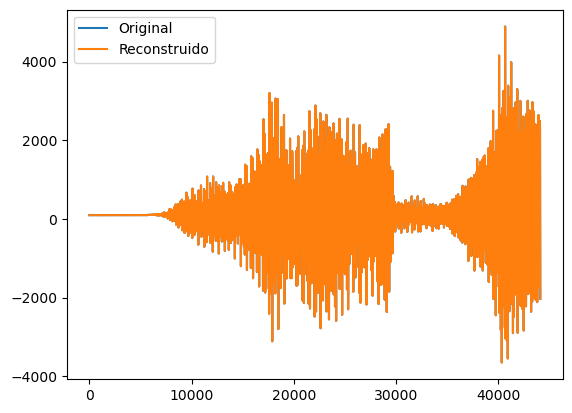

In [40]:
import matplotlib.pyplot as plt
plt.plot(samples[:44100], label="Original")
plt.plot(muestras_reconstruidas, label="Reconstruido")
plt.legend()
plt.show()

In [39]:
print(np.real(muestras_reconstruidas))

[   94.    94.    94. ... -1970. -2008. -2032.]


In [49]:
index_centroide=24
cluster_vectores=samples_vectors[etiquetas==index_centroide]

In [57]:
numero_muestras_cluster=cluster_vectores.shape[0]

In [55]:
centroide=np.round(centroides[index_centroide]).astype(int)

In [59]:
desviacion_estandar=np.std(cluster_vectores)

In [60]:
print(desviacion_estandar)

9518.308003746582


In [158]:
test_samples=np.array([2,2,4,5,7,7,7,7,7,9,10,11,11,15,19,19,19,21,22,24,24,27,30,31,33,33,34])

In [159]:
from collections import Counter
def get_stats(samples):
    media=np.mean(samples)
    desviacion_estandar=np.std(samples)
    mode=Counter(samples)
    num_samples=samples.shape[0]
    mediana=np.median(samples)
    minimo=np.min(samples)
    maximo=np.max(samples)
    return media,desviacion_estandar,mode.most_common()[0],num_samples,minimo,maximo,mediana

In [160]:
media,desviacion_estandar,mode,num_samples,minimo,maximo,mediana=get_stats(test_samples)

In [161]:
print(media,desviacion_estandar,mode,num_samples,minimo,maximo,mediana)

16.296296296296298 10.284165515813763 (7, 5) 27 2 34 15.0


In [168]:
new_samples_test = np.random.normal(media, desviacion_estandar, 4)

In [169]:
print(np.round(new_samples_test).astype(int))

[10 10 -5 16]


In [185]:
def generate_samples_from_stats(media_original, mediana_original, minimo_cluster,maximo_cluster, std_original, n_samples,moda_original=(1,1),error=0.01):
    samples_generated=np.zeros(n_samples)
    is_minimized=False
    is_impar=n_samples%2==1
    iteraciones=1
    errores={
        'media':[],
        'desviacion_estandar':[],
        'porcentage_error':[]
    }
    while not is_minimized:
        print('ITERACIONES ',iteraciones)
        is_minimized=True
        samples_generated = np.clip(samples_generated, minimo_cluster, maximo_cluster)
        samples_generated=np.sort(samples_generated)
        contador_errores = 0
        for index in range(n_samples):
            if test_samples[index] != samples_generated[index]:
                contador_errores += 1
        print(samples_generated)
        media, desviacion_estandar, mode, num_samples, minimo, maximo, mediana = (
            get_stats(samples_generated)
        )
        errores['porcentage_error'].append(contador_errores / n_samples)
        errores['media'].append(np.abs((media - media_original) / media_original))
        errores['desviacion_estandar'].append(np.abs((desviacion_estandar - std_original) / std_original))
        # media
        error_actual_media = np.abs((media - media_original) / media_original)
        if error_actual_media > error:
            print('Ajustando media...')
            print('Media actual ',media)
            print('Media deseada ',media_original)
            print('Error actual ',error_actual_media)
            is_minimized=False
            num_values_to_add = int(n_samples * 0.2)
            samples_to_add = np.round(
                np.random.normal(media_original, std_original, num_values_to_add)
            ).astype(int)
            if media > media_original:
                samples_generated[num_samples-num_values_to_add :] = samples_to_add
            elif media < media_original:
                samples_generated[:num_values_to_add] = samples_to_add
            samples_generated = np.sort(samples_generated)
            samples_generated = np.clip(samples_generated, minimo_cluster, maximo_cluster)
        # !media
        media, desviacion_estandar, mode, num_samples, minimo, maximo, mediana = (
            get_stats(samples_generated)
        )
        # desviacion estandar
        error_actual_std = np.abs((desviacion_estandar - std_original) / std_original)
        if error_actual_std > error:
            print('Ajustando desviacion estandar...')
            print('Desviacion estandar actual ',desviacion_estandar)
            print('Desviacion estandar deseada ',std_original)
            print('Error actual ',error_actual_std)
            is_minimized=False
            num_samples_to_add = int(n_samples * 0.2)
            if desviacion_estandar > std_original:
                # generar numeros enteros en el rango de media-desviacion_estandar, media-2*desviacion_estandar y media+desviacion_estandar,media+2*desviacion_estandar
                limite_inferior=int(media_original-std_original)
                limite_superior=int(media_original+std_original)
                numeros_aleatorios = np.random.randint(limite_inferior, limite_superior,num_samples_to_add)
                num_samples_to_add_inf=int(num_samples_to_add/2)
                num_samples_to_add_sup=num_samples_to_add-num_samples_to_add_inf
                samples_generated[:num_samples_to_add_inf]=numeros_aleatorios[:num_samples_to_add_inf]
                samples_generated[num_samples-num_samples_to_add_sup:]=numeros_aleatorios[num_samples_to_add_inf:]
            elif desviacion_estandar < std_original:
                # generar numeros enteros en el rango de media-desviacion_estandar y media+desviacion_estandar
                primer_limite_inferior=minimo_cluster#int(media_original-2*std_original)
                primer_limite_superior=int(media_original-std_original)
                segundo_limite_inferior=int(media_original+std_original)
                segundo_limite_superior=maximo_cluster#int(media_original+2*std_original)
                numeros_aleatorios_inferiores = np.random.randint(primer_limite_inferior, primer_limite_superior,int(n_samples*0.1))
                numeros_aleatorios_superiores = np.random.randint(segundo_limite_inferior, segundo_limite_superior,int(n_samples*0.1))
                samples_generated[int(n_samples/2)-len(numeros_aleatorios_inferiores):int(n_samples/2)]=numeros_aleatorios_inferiores
                samples_generated[int(n_samples/2):int(n_samples/2)+len(numeros_aleatorios_superiores)]=numeros_aleatorios_superiores
            samples_generated = np.sort(samples_generated)
            samples_generated = np.clip(samples_generated, minimo_cluster, maximo_cluster)
        # !desviacion estandar
        media, desviacion_estandar, mode, num_samples, minimo, maximo, mediana = (
            get_stats(samples_generated)
        )
        # moda
        moda_original_valor,moda_original_frecuencia=moda_original
        moda_actual_valor,moda_actual_frecuencia=mode
        if moda_original_frecuencia>1:
            media_rounded=np.round(media_original).astype(int)
            indices=np.where(samples_generated==moda_actual_valor)[0]
            if moda_actual_valor==moda_original_valor and moda_actual_frecuencia>moda_original_frecuencia:
                print('Moda igual a la original y mayor frecuencia')
                is_minimized=False
                diferencia_frecuencia=moda_actual_frecuencia-moda_original_frecuencia
                if moda_original_valor>media_rounded:
                    samples_generated[indices[:int(diferencia_frecuencia)]]=media_rounded
                elif moda_original_valor<media_rounded:
                    samples_generated[indices[len(indices)-int(diferencia_frecuencia):]]=media_rounded
                elif moda_original_valor==media_rounded:
                    num_values_to_add = int(diferencia_frecuencia)
                    samples_normal = np.round(
                        np.random.normal(media_original, std_original, num_values_to_add)
                    ).astype(int)
                    samples_generated[indices[len(indices)-num_values_to_add:]]=samples_normal                    
            elif moda_actual_valor==moda_original_valor and moda_actual_frecuencia<moda_original_frecuencia:
                print('Moda igual a la original y menor frecuencia')
                is_minimized=False
                diferencia_frecuencia=moda_original_frecuencia-moda_actual_frecuencia
                if moda_original_valor>media_rounded:
                    samples_generated[indices[:int(diferencia_frecuencia)]]=media_rounded
                elif moda_original_valor<media_rounded:
                    samples_generated[indices[len(indices)-int(diferencia_frecuencia):]]=media_rounded
                elif moda_original_valor==media_rounded:
                    num_values_to_add = int(diferencia_frecuencia)
                    samples_normal = np.round(
                        np.random.normal(media_original, std_original, num_values_to_add)
                    ).astype(int)
                    samples_generated[indices[len(indices)-num_values_to_add:]]=samples_normal
            elif moda_actual_valor!=moda_original_valor:
                print('Moda diferente a la original')
                is_minimized=False
                if moda_original_valor>moda_actual_valor:
                    samples_generated[indices[len(indices)-int(moda_original_frecuencia):]]=moda_original_valor
                elif moda_original_valor<moda_actual_valor:
                    samples_generated[indices[:int(moda_actual_frecuencia)]]=moda_original_valor
            samples_generated=np.sort(samples_generated)
        # !moda
        media, desviacion_estandar, mode, num_samples, minimo, maximo, mediana = (
            get_stats(samples_generated)
        )
        # mediana
        if mediana!=mediana_original:
            print('Ajustando mediana...')
            is_minimized=False
            if is_impar:
                samples_generated[int(n_samples/2)]=mediana_original
            else:
                samples_generated[int(n_samples/2)-1]=mediana_original
                samples_generated[int(n_samples/2)]=mediana_original
            samples_generated=np.sort(samples_generated)
        # !mediana

        # minimo
        if samples_generated[0]!=minimo_cluster:
            is_minimized=False
            samples_generated[0]=minimo_cluster
        # !minimo
        # maximo
        if samples_generated[-1]!=maximo_cluster:
            is_minimized=False
            samples_generated[-1]=maximo_cluster
        # !maximo
        samples_generated=samples_generated.astype(int)
        iteraciones+=1      
    return samples_generated,errores

In [186]:
samples_generated,errores=generate_samples_from_stats(media,mediana,minimo,maximo,desviacion_estandar,num_samples,mode)

ITERACIONES  1
[2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2.]
Ajustando media...
Media actual  2.0
Media deseada  16.296296296296298
Error actual  0.8772727272727273
Ajustando desviacion estandar...
Desviacion estandar actual  8.842161129671451
Desviacion estandar deseada  10.284165515813763
Error actual  0.14021598387588857
Moda diferente a la original
Ajustando mediana...
ITERACIONES  2
[ 2  2  2  2  2  2  2  2  2  2  2  2  2  4  7  7  7  7  7 15 16 17 21 29
 31 31 34]
Ajustando media...
Media actual  9.592592592592593
Media deseada  16.296296296296298
Error actual  0.4113636363636364
Ajustando desviacion estandar...
Desviacion estandar actual  11.358480935549318
Desviacion estandar deseada  10.284165515813763
Error actual  0.10446306198432931
Moda diferente a la original
Ajustando mediana...
ITERACIONES  3
[ 2  2  2  4  7  7  7  7  7  7  7  7  7  8  8 12 15 15 15 16 17 20 21 25
 25 29 34]
Ajustando media...
Media actual  12.333333333333334
Media 

In [187]:
def compare_samples(original,generated):
    media_original,desviacion_estandar_original,mode_original,num_samples_original,minimo_original,maximo_original,mediana_original=get_stats(original)
    media_generated,desviacion_estandar_generated,mode_generated,num_samples_generated,minimo_generated,maximo_generated,mediana_generated=get_stats(generated)
    print('Media original ',media_original)
    print('Media generada ',media_generated)
    print('Desviacion estandar original ',desviacion_estandar_original)
    print('Desviacion estandar generada ',desviacion_estandar_generated)
    print('Moda original ',mode_original)
    print('Moda generada ',mode_generated)
    print('Numero de muestras original ',num_samples_original)
    print('Numero de muestras generadas ',num_samples_generated)
    print('Minimo original ',minimo_original)
    print('Minimo generado ',minimo_generated)
    print('Maximo original ',maximo_original)
    print('Maximo generado ',maximo_generated)
    print('Mediana original ',mediana_original)
    print('Mediana generada ',mediana_generated)
    contador_errores=0
    for index in range(num_samples_original):
        if original[index]!=generated[index]:
            contador_errores+=1
    print('Errores ',contador_errores)
    print('Porcentaje de errores ',contador_errores/num_samples_original)
    print('Porcentaje de aciertos ',1-(contador_errores/num_samples_original))

In [188]:
print(test_samples)
print(samples_generated)

[ 2  2  4  5  7  7  7  7  7  9 10 11 11 15 19 19 19 21 22 24 24 27 30 31
 33 33 34]
[ 2  3  3  5  6  6  7  7  7  7  7 11 15 15 19 23 23 25 26 26 26 27 27 27
 29 31 34]


In [189]:
compare_samples(test_samples,samples_generated)

Media original  16.296296296296298
Media generada  16.444444444444443
Desviacion estandar original  10.284165515813763
Desviacion estandar generada  10.275224908175014
Moda original  (7, 5)
Moda generada  (7, 5)
Numero de muestras original  27
Numero de muestras generadas  27
Minimo original  2
Minimo generado  2
Maximo original  34
Maximo generado  34
Mediana original  15.0
Mediana generada  15.0
Errores  17
Porcentaje de errores  0.6296296296296297
Porcentaje de aciertos  0.37037037037037035


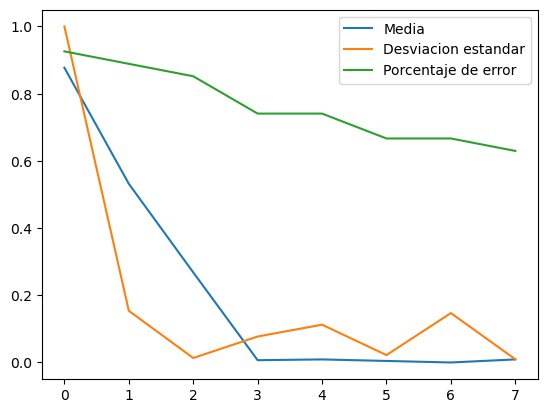

In [184]:
import matplotlib.pyplot as plt
plt.plot(errores['media'],label='Media')
plt.plot(errores['desviacion_estandar'],label='Desviacion estandar')
plt.plot(errores['porcentage_error'],label='Porcentaje de error')
plt.legend()
plt.show()